# Temperature-dependent viscoelasticity calibration

Polymer relaxation is temperature-dependent through time-temperature
superposition (TTS): relaxation times shift with temperature by an Arrhenius
factor, so relaxation curves at different temperatures are horizontal shifts of a
single master curve. The relaxation modulus of an $N$-branch Prony series is

$$E(t;T) = E_\infty + \sum_i E_i\,\exp\!\Big(\!-\frac{t}{\tau_i\,a_T(T)}\Big),
  \qquad a_T(T) = \exp\!\Big[\frac{Q}{R}\Big(\frac1T-\frac1{T_\text{ref}}\Big)\Big].$$

This demo shows **batched inference** of the response across 10 temperatures,
and **calibration** of the temperature-dependent parameters from noisy data,
using `jaxmat.constraints` so every physical parameter stays positive throughout.

In [35]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax
import paramax

from jaxmat.constraints import Positive
from jaxmat.parameters import Arrhenius  # the shift-factor law

jax.config.update("jax_enable_x64", True)

## Model

All moduli and times are `Positive()` fields (calibration cannot leave the
feasible region). The Arrhenius shift factor reuses `parameters.Arrhenius`.

In [36]:
T_REF = 300.0  # K


class ThermoViscoelastic(eqx.Module):
    E_inf: jax.Array = Positive()
    E: jax.Array = Positive()  # branch moduli (vector)
    tau: jax.Array = Positive()  # reference relaxation times (vector)
    Q: jax.Array = Positive()  # activation energy for the TTS shift

    def shift(self, T):
        # a_T(T) = exp[(Q/R)(1/T - 1/T_ref)]  (Arrhenius); reuse the parameter law
        return Arrhenius(A=1.0, Q=self.Q).evaluate(T) / Arrhenius(A=1.0, Q=self.Q).evaluate(T_REF)

    def relaxation_modulus(self, t, T):
        aT = self.shift(T)
        decays = jnp.exp(-t[:, None] / (self.tau[None, :] * aT))  # (n_t, n_branch)
        return self.E_inf + decays @ self.E


def unwrap_eval(model, t, T):
    return paramax.unwrap(model).relaxation_modulus(t, T)

## Ground-truth model and synthetic data

Two Prony branches with well-separated relaxation times; data are relaxation
moduli measured over log-spaced time at several temperatures, plus noise.

In [37]:
truth = ThermoViscoelastic(
    E_inf=200.0, E=jnp.array([800.0, 400.0]), tau=jnp.array([1.0, 100.0]), Q=6.0e4
)

t = jnp.logspace(-2, 4, 60)  # time [s]
T_data = jnp.array([280.0, 300.0, 320.0, 340.0])  # measurement temperatures [K]

key = jax.random.PRNGKey(0)
clean = jax.vmap(lambda T: unwrap_eval(truth, t, T))(T_data)  # (n_T, n_t)
noise = 15.0 * jax.random.normal(key, clean.shape)
data = clean + noise

## Batched inference across 10 temperatures

`vmap` evaluates the full relaxation curve at 10 temperatures at once -- the
curves shift left as temperature rises (faster relaxation), the TTS signature.

batched inference: (10, 60) (10 temperatures x 60 times)


Text(0.5, 1.0, 'Batched inference: 10 temperatures (TTS shift)')

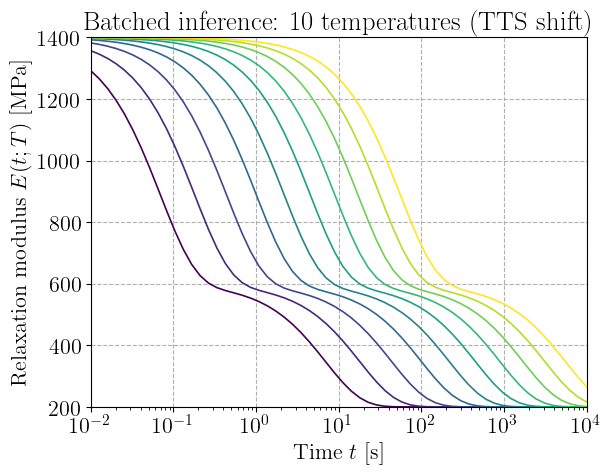

In [38]:
T_sweep = jnp.linspace(270.0, 360.0, 10)
curves = jax.jit(jax.vmap(lambda T: unwrap_eval(truth, t, T)))(T_sweep)
print("batched inference:", curves.shape, "(10 temperatures x", t.shape[0], "times)")

plt.figure()
for c, T in zip(curves, T_sweep):
    plt.semilogx(t, c, color=plt.cm.viridis((T - 270) / 90), lw=1.2)
plt.xlabel("Time $t$ [s]")
plt.ylabel("Relaxation modulus $E(t;T)$ [MPa]")
plt.title("Batched inference: 10 temperatures (TTS shift)")

## Calibration of the temperature-dependent parameters

In this section, we explore the calibration of the temperature-dependent viscoelastic model from
the noisy data which we just generated.
Starting from a wrong guess, we fit $E_\infty, E_i, \tau_i, Q$ to the noisy multi-temperature
data. Note that elastic parameters and parameters from the temperature model (here the activation
energy $Q$) are all packed together in the global model PyTree and calibrated simultaneously.

Because every parameter is declared `Positive()`, the model does not store the physical values
directly: it stores an unbounded latent parameter $z_{\theta_i}$ such that
$\theta_i = \exp(z_{\theta_i}) > 0$. These latents are the differentiable leaves of the PyTree, so
 the optimizer operates on them and no gradient step can ever make a parameter negative. Inside
the loss, `paramax.unwrap` is applied once to reconstruct the physical model parameters so that
stresses are computed with correctly-scaled, physical parameters. Automatic differentiation then
propagates the gradient back to the latent representations using the `Positive` $\exp$ mapping. A
useful side effect is that working in $\log$-space equalizes parameters spanning different orders
of magnitude (here $Q\sim10^4$, $E\sim 100$ and $\tau\sim 10$), since a step in $z_{\theta_i}$ is
a relative step in $\theta_i$. `adam(3e-2)`` is thus a ~3% relative step on each parameter, which
is sensible for all of them simultaneously.

In [39]:
model = ThermoViscoelastic(
    E_inf=100.0, E=jnp.array([500.0, 500.0]), tau=jnp.array([3.0, 30.0]), Q=3.0e4
)


def loss(model, T_data, data):
    pred = jax.vmap(lambda T: unwrap_eval(model, t, T))(T_data)
    return jnp.mean((pred - data) ** 2)


opt = optax.adam(3e-2)
opt_state = opt.init(eqx.filter(model, eqx.is_inexact_array))


@eqx.filter_jit
def step(model, opt_state):
    loss_value, g = eqx.filter_value_and_grad(loss)(model, T_data, data)
    updates, opt_state = opt.update(g, opt_state, model)
    return eqx.apply_updates(model, updates), opt_state, loss_value


for i in range(500):
    model, opt_state, loss_value = step(model, opt_state)
    if i % 50 == 0 or i == 499:
        print(f"step {i:5d}  loss = {float(loss_value):10.2f}")

fit = paramax.unwrap(model)
tru = paramax.unwrap(truth)
print("\nparameter recovery (fitted vs true):")
print(f"  E_inf : {float(fit.E_inf):7.1f}  vs {float(tru.E_inf):7.1f}")
print(f"  E     : {[round(float(x), 1) for x in fit.E]}  vs {[round(float(x), 1) for x in tru.E]}")
print(
    f"  tau   : {[round(float(x), 2) for x in fit.tau]}  vs {[round(float(x), 2) for x in tru.tau]}"
)
print(f"  Q     : {float(fit.Q):.3e}  vs {float(tru.Q):.3e}")

step     0  loss =   44421.00
step    50  loss =     765.32
step   100  loss =     252.54
step   150  loss =     232.53
step   200  loss =     231.45
step   250  loss =     231.43
step   300  loss =     231.43
step   350  loss =     231.43
step   400  loss =     231.43
step   450  loss =     231.43
step   499  loss =     231.43

parameter recovery (fitted vs true):
  E_inf :   197.6  vs   200.0
  E     : [799.0, 401.9]  vs [800.0, 400.0]
  tau   : [1.01, 98.78]  vs [1.0, 100.0]
  Q     : 5.998e+04  vs 6.000e+04


The calibration processes converges quickly recovering the ground truth value with a very good
accuracy.

## Results

We now compare the prediction of the fitted model against the noisy data for comparison, showing a
 very good calibration accuracy.

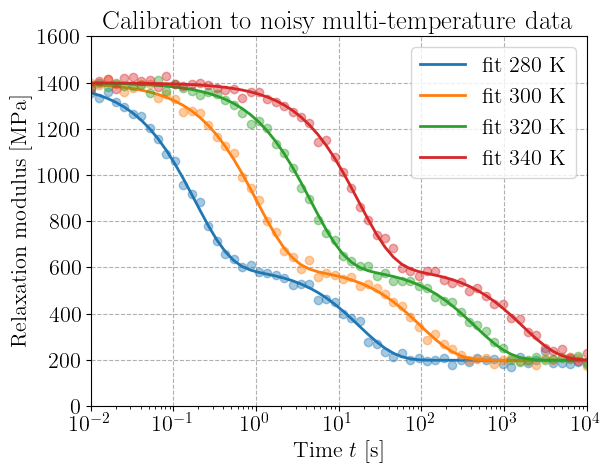

In [40]:
plt.figure()
for d, T in zip(data, T_data):
    h = plt.semilogx(t, d, "o", ms=6, alpha=0.4)
    plt.semilogx(
        t, unwrap_eval(fit, t, T), "-", color=h[0].get_color(), lw=2.0, label=f"fit {int(T)} K"
    )
plt.xlabel("Time $t$ [s]")
plt.ylabel("Relaxation modulus [MPa]")
plt.title("Calibration to noisy multi-temperature data")
plt.legend()

Finally, we check that the time-temperature superposition is well retried by plotting the master
curve of the relaxation modulus as a function of the reduced time $\tilde{t} = t/a(T)$.

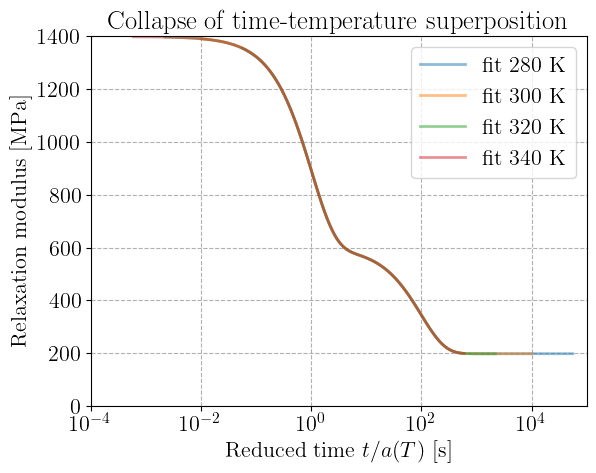

In [41]:
plt.figure()
for d, T in zip(data, T_data):
    # h = plt.semilogx(t, d, "o", ms=6, alpha=0.4)
    plt.semilogx(
        t / fit.shift(T),
        unwrap_eval(fit, t, T),
        "-",
        lw=2.0,
        alpha=0.5,
        label=f"fit {int(T)} K",
    )
plt.xlabel("Reduced time $t/a(T)$ [s]")
plt.ylabel("Relaxation modulus [MPa]")
plt.title("Collapse of time-temperature superposition")
plt.legend()